In [2]:
import sys, json, math
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt

from eudr import boundaries as bd, screening as scr
from eudr.config import load_config, run_dirs, slugify, resolve_path
from eudr.manifest import write_manifest

warnings.filterwarnings("ignore", category=UserWarning)
cfg = load_config(ROOT)
dirs = run_dirs(cfg)

H = cfg["forest_data"]["hansen"]
THR = H["treecover_threshold"]
CUT_YEAR = int(cfg["eudr"]["cutoff_date"][:4])
CUT_CODE = CUT_YEAR - 2000
SC = cfg["screening"]

baseline = "Hansen proxy: tree cover 2000 minus loss to 2020 (not the EUDR reference map)"
print("2020 forest baseline:", baseline)

2020 forest baseline: Hansen proxy: tree cover 2000 minus loss to 2020 (not the EUDR reference map)


In [3]:
gpkg = dirs["gis"] / "plots_validated.gpkg"
polys = gpd.read_file(gpkg, layer="plots_polygons")
pts = gpd.read_file(gpkg, layer="plots_points")
plots = gpd.GeoDataFrame(pd.concat([polys, pts], ignore_index=True), geometry="geometry", crs=4326)

all_plots = pd.read_excel(dirs["reports"] / "plot_data_quality_report.xlsx", sheet_name="plots")
no_geom = all_plots[~all_plots["plot_id"].isin(plots["plot_id"])].copy()
print(f"{len(plots)} plots with geometry; {len(no_geom)} without (cannot be screened)")
print("Notebook 03 status:", plots["status"].value_counts().to_dict())

districts = gpd.read_file(dirs["gis"] / "study_area.gpkg", layer="ref_districts")
subcounties = gpd.read_file(dirs["gis"] / "study_area.gpkg", layer="ref_subcounties")
study = shapely.make_valid(shapely.union_all(subcounties.geometry.values))

392 plots with geometry; 8 without (cannot be screened)
Notebook 03 status: {'pass': 282, 'review': 72, 'reject': 38}


In [4]:
reserves = scr.load_reserves(study, SC, lambda p: resolve_path(cfg, p))
if reserves is None:
    print("No protected-area layer in use. Set screening.protected_areas_path or use_osm_reserves in config.yaml.")
else:
    print(f"{len(reserves)} protected-area polygons loaded:", sorted(reserves['pa_name'].unique())[:10])

No protected-area layer in use. Set screening.protected_areas_path or use_osm_reserves in config.yaml.


In [5]:
prep = scr.prepare_geometries(plots, SC)
work = pd.DataFrame(plots.drop(columns="geometry")).join(prep)

print("Screening basis    :", work.loc[work["not_screened_reason"] == "", "basis"].value_counts().to_dict())
print("Confidence         :", work.loc[work["not_screened_reason"] == "", "confidence"].value_counts().to_dict())
print("Cannot be screened :", work.loc[work["not_screened_reason"] != "", "not_screened_reason"].value_counts().to_dict())

Screening basis    : {'polygon': 224, 'point_buffer': 148, 'polygon_repaired': 8}
Confidence         : {'low': 156, 'high': 153, 'medium': 71}
Cannot be screened : {'blocked by: outside_study_area': 6, 'blocked by: outside_uganda': 6}


In [6]:
rasters, rows = {}, []
todo = work[work["not_screened_reason"] == ""]

for dname, grp in todo.groupby("district_spatial"):
    R = rasters[dname] = scr.load_rasters(dirs, slugify(dname), H["version"], THR)
    print(f"{dname}: screening {len(grp)} plots")
    for i, r in grp.iterrows():
        m = scr.screen_geometry(r["geom_screen"], R, CUT_CODE)
        mb = scr.screen_geometry(r["geom_buffered"], R, CUT_CODE)       # same plot widened by its GPS accuracy
        if m is None or mb is None:
            rows.append({"idx": i, "raster_note": "outside raster extent"})
            continue
        res_pct, res_names = scr.reserve_share(r["geom_screen"], reserves)
        flag, prio, why = scr.classify(m, r, SC, CUT_YEAR, res_pct, res_names)
        flag_b, _, _ = scr.classify(mb, r, SC, CUT_YEAR, res_pct, res_names)
        rows.append({"idx": i, **m, "reserve_overlap_pct": round(res_pct, 1), "reserve_names": res_names,
                     "risk_flag": flag, "priority": prio, "reasons": why,
                     "risk_flag_gps_buffer": flag_b, "gps_buffer_changes_flag": flag != flag_b})

res = pd.DataFrame(rows).set_index("idx")

for col in ["raster_note", "risk_flag", "priority", "gps_buffer_changes_flag"]:
    if col not in res.columns:
        res[col] = np.nan

risk = work.drop(columns=["geom_screen", "geom_buffered"]).join(res)
risk["not_screened_reason"] = np.where(risk["raster_note"].notna(),
                                       risk["raster_note"], risk["not_screened_reason"])
risk["risk_flag"] = risk["risk_flag"].fillna("not screened")
risk["priority"] = risk["priority"].fillna("n/a")
risk = risk.drop(columns="raster_note")
risk_gdf = gpd.GeoDataFrame(risk, geometry=plots.geometry, crs=4326)

print(risk["risk_flag"].value_counts().to_dict())
print("risk_gdf created:", len(risk_gdf), "rows")

Buikwe: screening 190 plots
Kyotera: screening 190 plots
{'no loss': 279, 'review': 60, 'possible loss': 41, 'not screened': 12}
risk_gdf created: 392 rows


In [7]:
ORDER = ["possible loss", "review", "no loss", "not screened"]

def flag_table(df, by):
    t = pd.crosstab(df[by], df["risk_flag"]).reindex(columns=ORDER, fill_value=0)
    t["plots"] = t.sum(axis=1)
    t["possible_loss_pct"] = (t["possible loss"] / t["plots"] * 100).round(1)
    return t.reset_index()

by_district = flag_table(risk, "district")
by_subcounty = flag_table(risk, "subcounty")
area_by_flag = (risk.groupby("risk_flag")["declared_area_ha"].agg(plots="count", declared_area_ha="sum").round(1)
                .reindex(ORDER).reset_index())
sensitive = int(risk["gps_buffer_changes_flag"].fillna(False).sum())

display(by_district)
display(area_by_flag)
print(f"Flags that change when the plot is widened by its GPS accuracy: {sensitive}")

high = (risk[risk["priority"] == "high"]
        .sort_values(["loss_post_in_forest_ha"], ascending=False)
        [["plot_id", "farmer_id", "district", "subcounty", "risk_flag", "loss_year_first",
          "loss_post_in_forest_ha", "forest2020_pct" if "forest2020_pct" in risk else "forest2020_ha",
          "confidence", "gps_buffer_changes_flag", "reasons"]])
display(high.head(15))

risk_flag,district,possible loss,review,no loss,not screened,plots,possible_loss_pct
0,Buikwe,25,45,120,6,196,12.8
1,Kyotera,16,15,159,6,196,8.2


,risk_flag,plots,declared_area_ha
0,possible loss,41,189.4
1,review,60,159.8
2,no loss,279,424.7
3,not screened,12,10.3


Flags that change when the plot is widened by its GPS accuracy: 8


,plot_id,farmer_id,district,subcounty,risk_flag,loss_year_first,loss_post_in_forest_ha,forest2020_ha,confidence,gps_buffer_changes_flag,reasons
8,SYN-BUI-0016,F-BUI-0145,Buikwe,Lugazi Municipality,possible loss,2021.0,15.473762,49.388692,high,False,15.47 ha tree loss after 2020 on land that was...
14,SYN-BUI-0029,F-BUI-0134,Buikwe,KCCA,possible loss,2021.0,3.613399,28.483731,high,False,3.61 ha tree loss after 2020 on land that was ...
56,SYN-BUI-0112,F-BUI-0157,Buikwe,Buikwe,possible loss,2023.0,1.564088,2.627420,high,False,1.56 ha tree loss after 2020 on land that was ...
170,SYN-KYO-0087,F-KYO-0077,Kyotera,Kyotera,possible loss,2024.0,0.927278,0.955096,high,False,0.93 ha tree loss after 2020 on land that was ...
241,SYN-BUI-0018,F-BUI-0112,Buikwe,Lugazi Municipality,possible loss,2021.0,0.905671,1.601151,low,False,0.91 ha tree loss after 2020 on land that was ...
28,SYN-BUI-0057,F-BUI-0102,Buikwe,Njeru Municipality,possible loss,2021.0,0.741841,1.007667,high,False,0.74 ha tree loss after 2020 on land that was ...
271,SYN-BUI-0084,F-BUI-0038,Buikwe,Buikwe,possible loss,2023.0,0.720221,0.843864,low,False,0.72 ha tree loss after 2020 on land that was ...
103,SYN-BUI-0182,F-BUI-0139,Buikwe,Buikwe,possible loss,2021.0,0.701675,0.757314,high,False,0.70 ha tree loss after 2020 on land that was ...
156,SYN-KYO-0067,F-KYO-0079,Kyotera,Kyotera,possible loss,2023.0,0.695441,2.321229,high,False,0.70 ha tree loss after 2020 on land that was ...
84,SYN-BUI-0153,F-BUI-0102,Buikwe,Buikwe,possible loss,2025.0,0.630579,0.850045,high,False,0.63 ha tree loss after 2020 on land that was ...


In [8]:
truth_path = ROOT / "data" / "synthetic" / "plots_synthetic_truth.csv"
if truth_path.exists():
    EXPECTED = {"clean": "no loss", "near_forest": "no loss", "inside_forest": "review",
                "loss_in_forest": "possible loss", "loss_outside": "review"}
    t = risk.merge(pd.read_csv(truth_path), on="plot_id", how="inner")
    t = t[t["risk_flag"] != "not screened"].copy()
    t["expected"] = t["_truth_scenario"].map(EXPECTED)
    display(pd.crosstab(t["_truth_scenario"], t["risk_flag"]).reindex(columns=ORDER[:3], fill_value=0))
    screening_test = (t.groupby("_truth_scenario")
                      .apply(lambda g: pd.Series({"plots": len(g),
                                                  "expected_flag": g["expected"].iloc[0],
                                                  "match_pct": round((g["risk_flag"] == g["expected"]).mean() * 100)}),
                             include_groups=False).reset_index())
    display(screening_test)
else:
    screening_test = pd.DataFrame()
    print("No synthetic truth file found; skipping the test.")

risk_flag,possible loss,review,no loss
_truth_scenario,,,
clean,8,28,193
inside_forest,2,22,0
loss_in_forest,30,0,0
near_forest,1,10,86


,_truth_scenario,plots,expected_flag,match_pct
0,clean,229,no loss,84
1,inside_forest,24,review,92
2,loss_in_forest,30,possible loss,100
3,near_forest,97,no loss,89


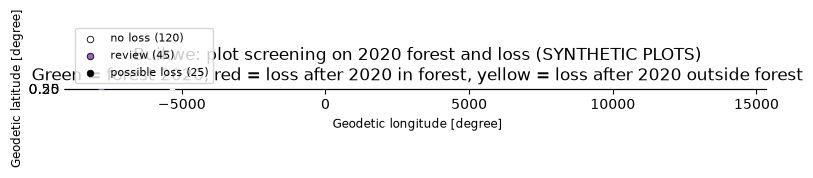

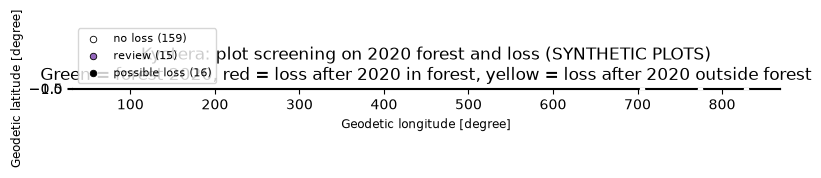

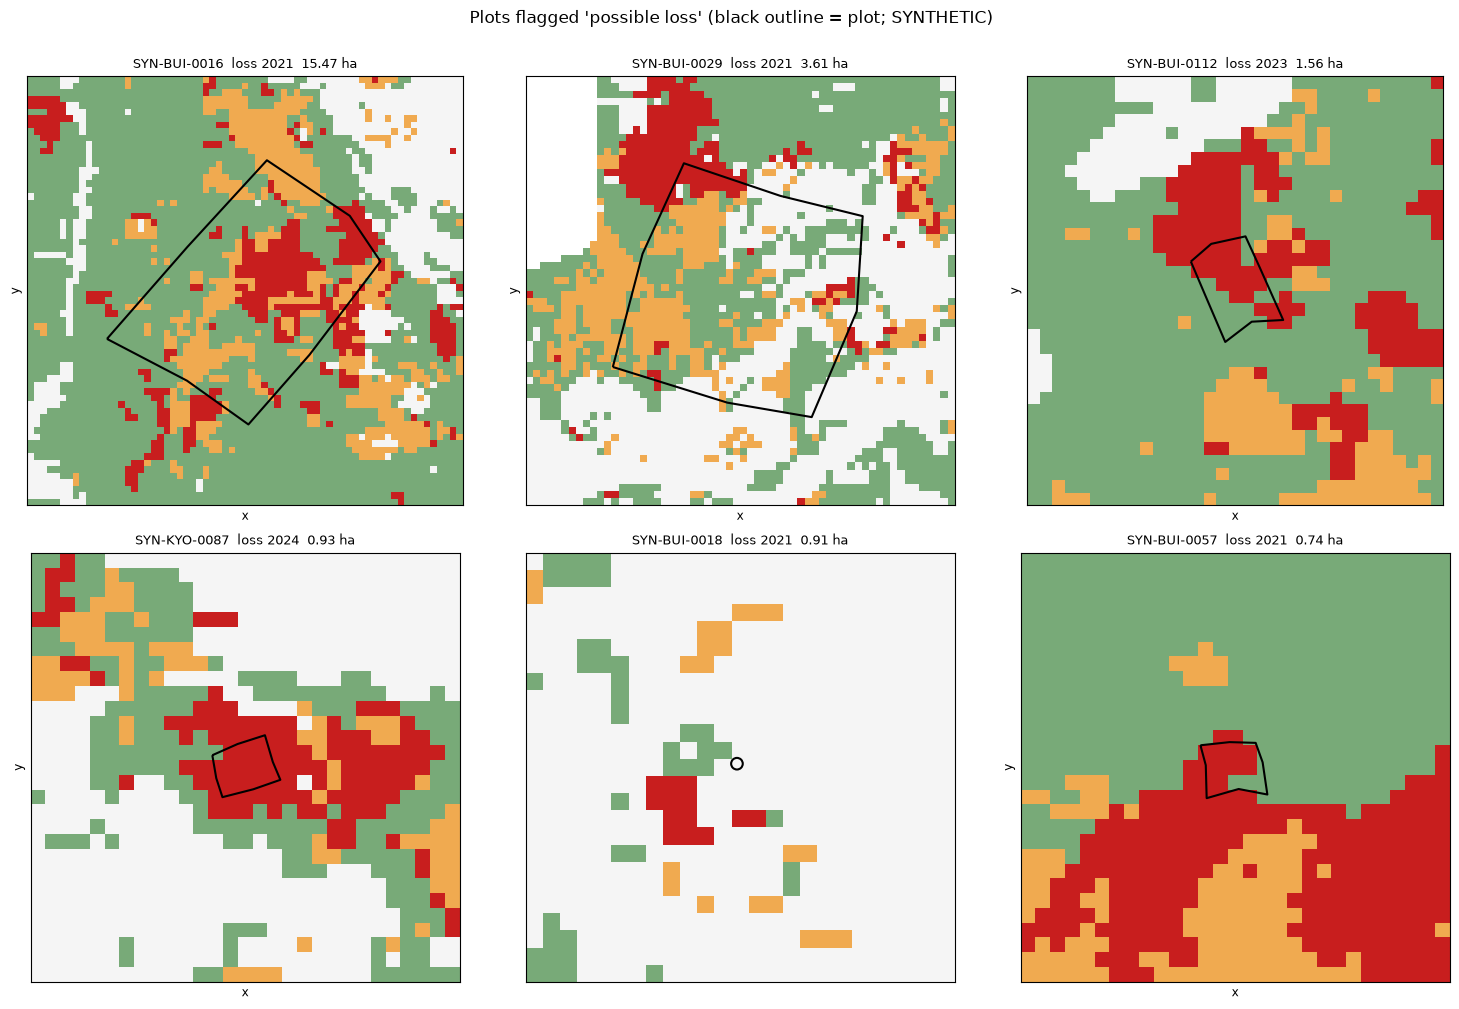

In [9]:
MARK = {"no loss": "white", "review": "#9467bd", "possible loss": "black"}

for dname, R in rasters.items():
    h, w = R.shape
    tr = R.tr
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(scr.class_rgb(R), extent=(tr.c, tr.c + w * tr.a, tr.f + h * tr.e, tr.f))
    subcounties[subcounties["district"] == dname].boundary.plot(ax=ax, color="grey", linewidth=0.4)
    v = risk_gdf[(risk_gdf["district_spatial"] == dname) & (risk_gdf["risk_flag"] != "not screened")]
    c = shapely.centroid(v.geometry.to_numpy())
    x, y = shapely.get_x(c), shapely.get_y(c)
    for flag, color in MARK.items():
        m = (v["risk_flag"] == flag).to_numpy()
        ax.scatter(x[m], y[m], s=22, facecolor=color, edgecolor="black", linewidth=0.6,
                   label=f"{flag} ({m.sum()})", zorder=3)
    ax.legend(loc="lower left", fontsize=8)
    ax.set_title(f"{dname}: plot screening on 2020 forest and loss (SYNTHETIC PLOTS)\n"
                 f"Green = forest 2020, red = loss after {CUT_YEAR} in forest, yellow = loss after {CUT_YEAR} outside forest")
    fig.tight_layout()
    fig.savefig(dirs["maps"] / f"{slugify(dname)}_plot_screening.png", dpi=200)
    plt.show()

# Evidence panels for the highest-priority plots
top = (risk_gdf[risk_gdf["risk_flag"] == "possible loss"]
       .sort_values("loss_post_in_forest_ha", ascending=False).head(SC["top_panels"]))
if len(top):
    ncols = 3
    nrows = math.ceil(len(top) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), top.iterrows()):
        R = rasters[r["district_spatial"]]
        tr, pad = R.tr, 0.003                                    # about 330 m around the plot
        minx, miny, maxx, maxy = r.geometry.bounds
        c0, c1 = max(int((minx - pad - tr.c) / tr.a), 0), min(int((maxx + pad - tr.c) / tr.a) + 1, R.shape[1])
        r0, r1 = max(int((maxy + pad - tr.f) / tr.e), 0), min(int((miny - pad - tr.f) / tr.e) + 1, R.shape[0])
        ax.axis("on")
        ax.imshow(scr.class_rgb(R)[r0:r1, c0:c1],
                  extent=(tr.c + c0 * tr.a, tr.c + c1 * tr.a, tr.f + r1 * tr.e, tr.f + r0 * tr.e))
        if r.geometry.geom_type == "Point":
            ax.scatter([r.geometry.x], [r.geometry.y], s=70, facecolor="none", edgecolor="black", linewidth=1.5)
        else:
            gpd.GeoSeries([r.geometry]).boundary.plot(ax=ax, color="black", linewidth=1.5)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{r['plot_id']}  loss {r['loss_year_first']:.0f}  {r['loss_post_in_forest_ha']:.2f} ha", fontsize=9)
    fig.suptitle("Plots flagged 'possible loss' (black outline = plot; SYNTHETIC)", y=1.0)
    fig.tight_layout()
    fig.savefig(dirs["maps"] / "evidence_panels.png", dpi=200)
    plt.show()
else:
    print("No plots flagged 'possible loss', so no evidence panels.")

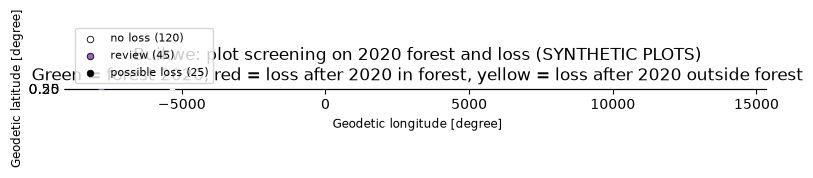

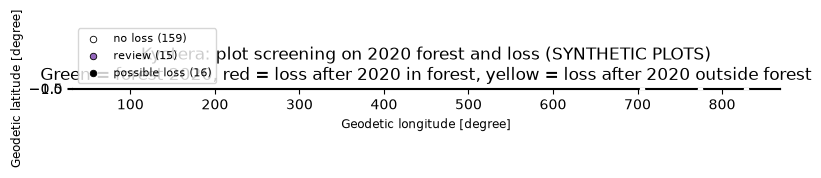

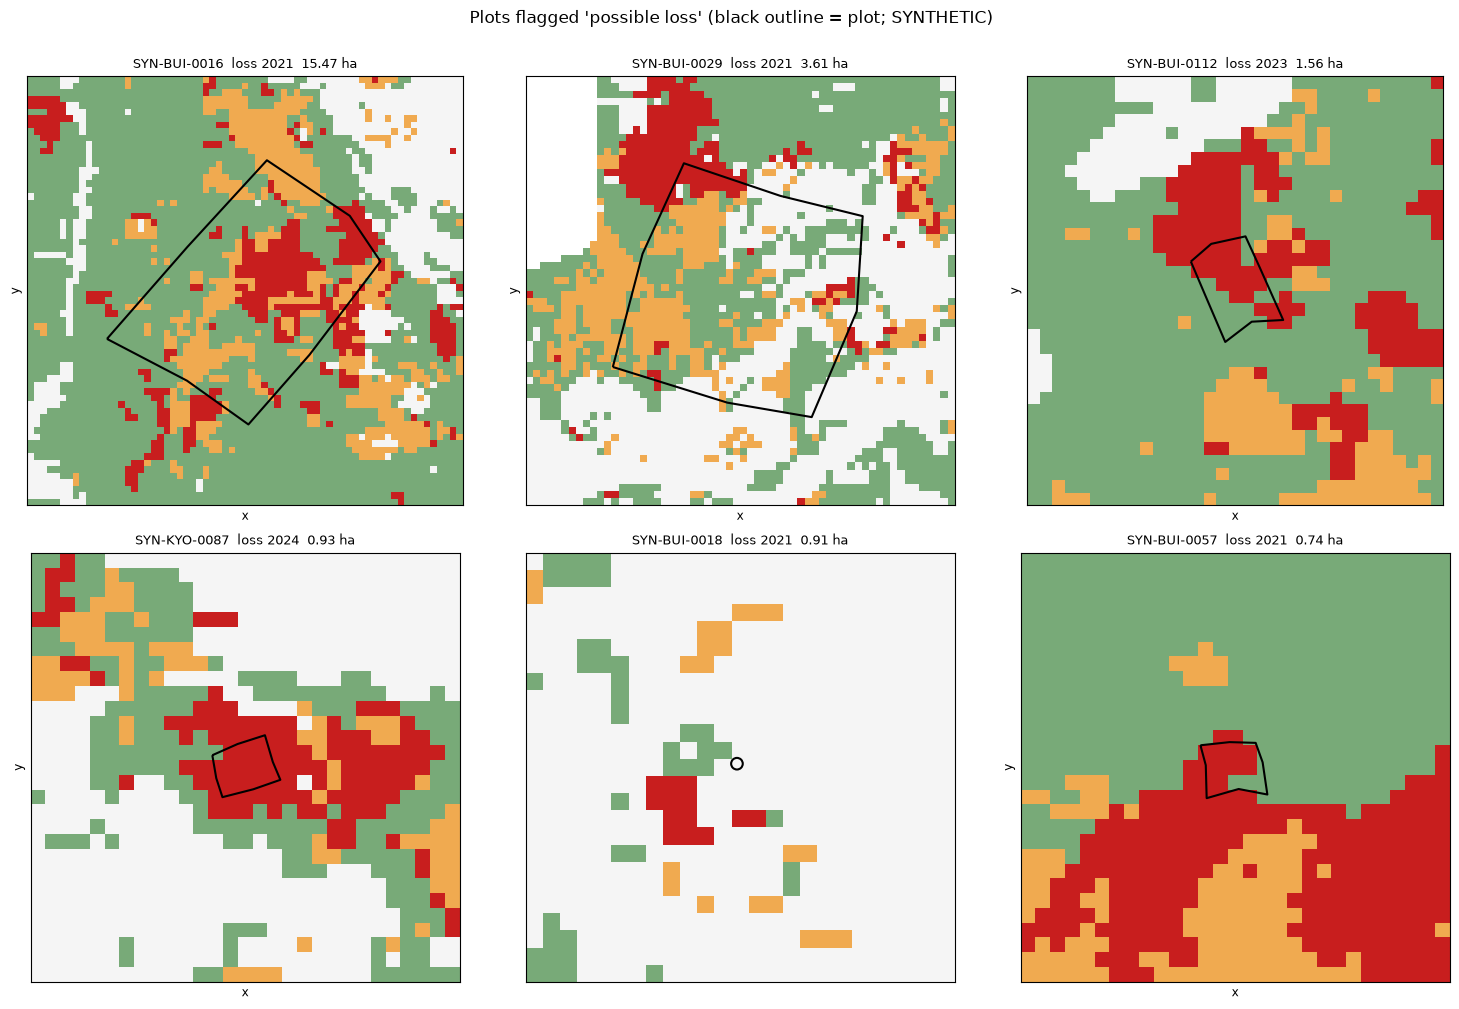

In [10]:
MARK = {"no loss": "white", "review": "#9467bd", "possible loss": "black"}

for dname, R in rasters.items():
    h, w = R.shape
    tr = R.tr
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(scr.class_rgb(R), extent=(tr.c, tr.c + w * tr.a, tr.f + h * tr.e, tr.f))
    subcounties[subcounties["district"] == dname].boundary.plot(ax=ax, color="grey", linewidth=0.4)
    v = risk_gdf[(risk_gdf["district_spatial"] == dname) & (risk_gdf["risk_flag"] != "not screened")]
    c = shapely.centroid(v.geometry.to_numpy())
    x, y = shapely.get_x(c), shapely.get_y(c)
    for flag, color in MARK.items():
        m = (v["risk_flag"] == flag).to_numpy()
        ax.scatter(x[m], y[m], s=22, facecolor=color, edgecolor="black", linewidth=0.6,
                   label=f"{flag} ({m.sum()})", zorder=3)
    ax.legend(loc="lower left", fontsize=8)
    ax.set_title(f"{dname}: plot screening on 2020 forest and loss (SYNTHETIC PLOTS)\n"
                 f"Green = forest 2020, red = loss after {CUT_YEAR} in forest, yellow = loss after {CUT_YEAR} outside forest")
    fig.tight_layout()
    fig.savefig(dirs["maps"] / f"{slugify(dname)}_plot_screening.png", dpi=200)
    plt.show()

# Evidence panels for the highest-priority plots
top = (risk_gdf[risk_gdf["risk_flag"] == "possible loss"]
       .sort_values("loss_post_in_forest_ha", ascending=False).head(SC["top_panels"]))
if len(top):
    ncols = 3
    nrows = math.ceil(len(top) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), top.iterrows()):
        R = rasters[r["district_spatial"]]
        tr, pad = R.tr, 0.003                                    # about 330 m around the plot
        minx, miny, maxx, maxy = r.geometry.bounds
        c0, c1 = max(int((minx - pad - tr.c) / tr.a), 0), min(int((maxx + pad - tr.c) / tr.a) + 1, R.shape[1])
        r0, r1 = max(int((maxy + pad - tr.f) / tr.e), 0), min(int((miny - pad - tr.f) / tr.e) + 1, R.shape[0])
        ax.axis("on")
        ax.imshow(scr.class_rgb(R)[r0:r1, c0:c1],
                  extent=(tr.c + c0 * tr.a, tr.c + c1 * tr.a, tr.f + r1 * tr.e, tr.f + r0 * tr.e))
        if r.geometry.geom_type == "Point":
            ax.scatter([r.geometry.x], [r.geometry.y], s=70, facecolor="none", edgecolor="black", linewidth=1.5)
        else:
            gpd.GeoSeries([r.geometry]).boundary.plot(ax=ax, color="black", linewidth=1.5)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{r['plot_id']}  loss {r['loss_year_first']:.0f}  {r['loss_post_in_forest_ha']:.2f} ha", fontsize=9)
    fig.suptitle("Plots flagged 'possible loss' (black outline = plot; SYNTHETIC)", y=1.0)
    fig.tight_layout()
    fig.savefig(dirs["maps"] / "evidence_panels.png", dpi=200)
    plt.show()
else:
    print("No plots flagged 'possible loss', so no evidence panels.")

In [12]:
# ---------- save for QGIS and write forest_screening_report.xlsx ----------
# needs: risk, risk_gdf, plots, no_geom, by_district, by_subcounty, area_by_flag, high, screening_test,
#        sensitive, baseline, reserves, ORDER (all created by the cells above)

# 1. clean types so the GeoPackage writer does not choke on mixed object columns
risk["gps_buffer_changes_flag"] = risk["gps_buffer_changes_flag"].fillna(False).astype(bool)
risk_gdf = gpd.GeoDataFrame(risk, geometry=plots.geometry, crs=4326)

# 2. GeoPackage for QGIS
out_gpkg = dirs["gis"] / "plots_risk.gpkg"
if out_gpkg.exists():
    out_gpkg.unlink()
g = risk_gdf[risk_gdf.geometry.notna() & ~risk_gdf.geometry.is_empty]
g_poly = g[g.geom_type.isin(["Polygon", "MultiPolygon"])]
g_pt = g[g.geom_type == "Point"]
if len(g_poly):
    g_poly.to_file(out_gpkg, layer="risk_polygons", driver="GPKG")
if len(g_pt):
    g_pt.to_file(out_gpkg, layer="risk_points", driver="GPKG")

# 3. extra summary tables
quality_vs_risk = (pd.crosstab(risk["status"], risk["risk_flag"])
                   .reindex(columns=ORDER, fill_value=0).reset_index())          # data quality x forest risk

ha_by_district = (risk.pivot_table(index="district", columns="risk_flag", values="declared_area_ha",
                                   aggfunc="sum", fill_value=0)
                  .reindex(columns=ORDER, fill_value=0).round(1).reset_index())  # declared hectares by flag

flagged = risk[risk["risk_flag"].isin(["possible loss", "review"]) & risk["loss_year_first"].notna()]
flag_by_year = (flagged.groupby(["district", "loss_year_first", "risk_flag"]).size()
                .reset_index(name="plots"))

lead = ["plot_id", "farmer_id", "district", "subcounty", "enumerator_id", "cooperative_or_group",
        "status", "risk_flag", "priority", "reasons", "declared_area_ha", "geometry_type", "confidence",
        "basis", "forest2020_ha", "loss_post2020_ha", "loss_post_in_forest_ha",
        "loss_post_outside_forest_ha", "loss_year_first", "dist_to_forest_m", "reserve_overlap_pct",
        "gps_buffer_changes_flag", "risk_flag_gps_buffer", "year_established", "previous_land_use",
        "lat", "lon", "not_screened_reason"]
full = pd.concat([pd.DataFrame(risk),
                  no_geom.assign(risk_flag="not screened", priority="n/a", not_screened_reason="no geometry")],
                 ignore_index=True)
full = full[[c for c in lead if c in full.columns] + [c for c in full.columns if c not in lead]]
full = full.replace([np.inf, -np.inf], np.nan)          # Excel cannot store infinity

# 4. writer with formatting
def write_sheet(xl, df, name, flag_col=None):
    df.to_excel(xl, sheet_name=name, index=False)
    ws = xl.sheets[name]
    ws.freeze_panes(1, 0)
    for k, col in enumerate(df.columns):
        longest = int(df[col].astype(str).str.len().quantile(0.9)) + 2 if len(df) else 10
        ws.set_column(k, k, min(45, max(len(str(col)) + 2, longest)))
    if flag_col and flag_col in df.columns and len(df):
        k = list(df.columns).index(flag_col)
        for value, color in (("possible loss", "#F8CBAD"), ("review", "#FFE699"),
                             ("no loss", "#C6E0B4"), ("not screened", "#D9D9D9")):
            ws.conditional_format(1, k, len(df), k, {"type": "cell", "criteria": "==", "value": f'"{value}"',
                                  "format": xl.book.add_format({"bg_color": color})})

notes = pd.DataFrame({"note": [
    "SYNTHETIC DATA: plots, farmers and coordinates are generated for testing.",
    f"2020 forest baseline: {baseline}",
    f"Tree loss: Hansen {H['version']}, tree cover threshold {THR}%, cut-off {cfg['eudr']['cutoff_date']}.",
    "With the Hansen proxy, post-2020 loss always counts as 'inside 2020 forest', so loss outside forest is 0.",
    "Flags are screening results that trigger review. They are not proof of deforestation.",
    "possible loss = significant tree loss after the cut-off on land that was forest in 2020, or coffee declared "
    "as established after the cut-off on 2020 forest.",
    "review = loss outside the 2020 forest map, forest cover with no loss, contradictory declarations, or a protected area.",
    f"Thresholds: loss of at least {SC['min_loss_ha']} ha and {SC['min_loss_pct']}% of the plot; "
    f"forest overlap of {SC['forest_overlap_pct']}% or more.",
    "Point plots are screened as a circle of their declared area (low confidence).",
    f"gps_buffer_changes_flag = TRUE ({sensitive} plots) means the flag depends on the plot's exact location.",
    "Protected-area layer: " + ("not used" if reserves is None else f"{len(reserves)} polygons"),
    "Subcounty results depend on the boundary layer used in notebook 01."]})

report = dirs["reports"] / "forest_screening_report.xlsx"
with pd.ExcelWriter(report, engine="xlsxwriter") as xl:
    write_sheet(xl, area_by_flag, "summary")
    write_sheet(xl, by_district, "by_district")
    write_sheet(xl, ha_by_district, "hectares_by_district")
    write_sheet(xl, quality_vs_risk, "quality_vs_risk")
    write_sheet(xl, high, "high_priority")
    write_sheet(xl, flag_by_year, "flags_by_loss_year")
    write_sheet(xl, by_subcounty, "by_subcounty")
    write_sheet(xl, full, "plots_screened", flag_col="risk_flag")
    write_sheet(xl, screening_test, "screening_test")
    write_sheet(xl, notes, "notes")

write_manifest(dirs["manifests"], "04_plot_screening", {
    "baseline_2020": baseline,
    "hansen_version": H["version"],
    "cutoff_year": CUT_YEAR,
    "screening_settings": SC,
    "protected_areas_loaded": None if reserves is None else int(len(reserves)),
    "flag_counts": risk["risk_flag"].value_counts().to_dict(),
    "gps_sensitive_flags": sensitive,
})
print("Saved:", out_gpkg)
print("Saved:", report)
print("Rows in plots_screened:", len(full), "| flag counts:", full["risk_flag"].value_counts().to_dict())

Saved: C:\Users\shyak\Downloads\eudr-coffee-uganda\outputs\buikwe_kyotera\gis\plots_risk.gpkg
Saved: C:\Users\shyak\Downloads\eudr-coffee-uganda\outputs\buikwe_kyotera\reports\forest_screening_report.xlsx
Rows in plots_screened: 400 | flag counts: {'no loss': 279, 'review': 60, 'possible loss': 41, 'not screened': 20}
